## Libraries

In [3]:
from utils.data_loader import load_mnist
from utils.plots import plot_sample_images, plot_training_history
from utils.models import build_lenet5_mnist

## Loading MNIST dataset

In [4]:
(X_train_lenet5_mnist, y_train_lenet5_mnist), (X_test_lenet5_mnist, y_test_lenet5_mnist) = load_mnist(flatten=False)
print(f"X_train: {X_train_lenet5_mnist.shape}, y_train: {y_train_lenet5_mnist.shape}")
print(f"X_test: {X_test_lenet5_mnist.shape}, y_test: {y_test_lenet5_mnist.shape}")

X_train: (60000, 28, 28, 1), y_train: (60000, 10)
X_test: (10000, 28, 28, 1), y_test: (10000, 10)


## Show MNIST dataset images 

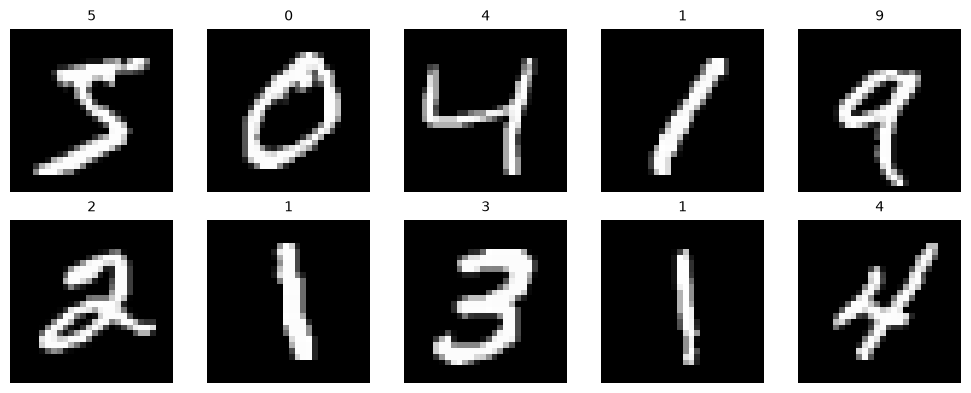

In [5]:
plot_sample_images(X_train_lenet5_mnist[:10], y_train_lenet5_mnist[:10])


## Model implementation and training

In [6]:
lenet_mnist = build_lenet5_mnist(learning_rate=0.001)
lenet_mnist.summary()

E0000 00:00:1791675013.936832   28706 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Entraînement
history_lenet = lenet_mnist.fit(
    X_train_lenet5_mnist,
    y_train_lenet5_mnist,
    validation_data=(X_test_lenet5_mnist, y_test_lenet5_mnist),
    epochs=10,
    batch_size=64
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.9208 - loss: 0.2569 - val_accuracy: 0.9742 - val_loss: 0.0779
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9762 - loss: 0.0790 - val_accuracy: 0.9837 - val_loss: 0.0543
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9827 - loss: 0.0563 - val_accuracy: 0.9830 - val_loss: 0.0566
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9864 - loss: 0.0445 - val_accuracy: 0.9882 - val_loss: 0.0366
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9880 - loss: 0.0372 - val_accuracy: 0.9883 - val_loss: 0.0350
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9898 - loss: 0.0312 - val_accuracy: 0.9896 - val_loss: 0.0313
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9908 - loss: 0.0272 - val_accuracy: 0.9908 - val_loss: 0.0281
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9926 - loss: 0.0225 - 

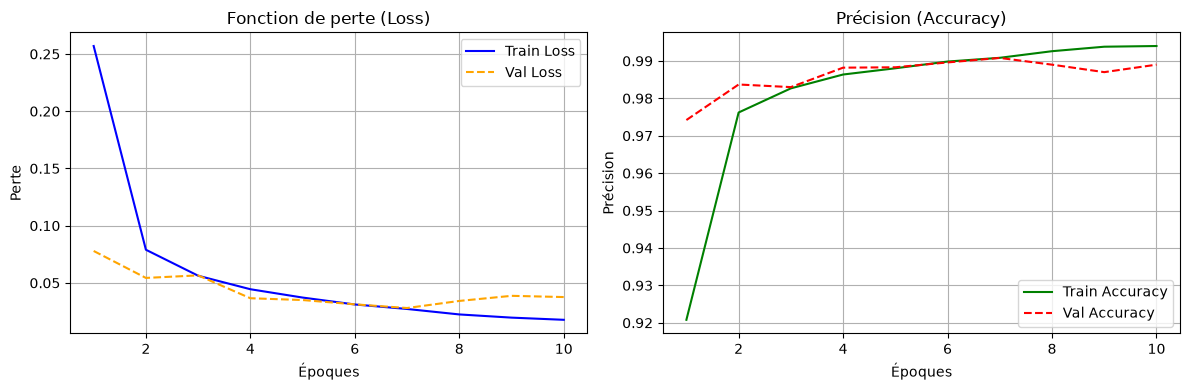

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9890 - loss: 0.0376
Précision LeNet-5 sur MNIST : 98.90%


In [8]:
plot_training_history(history_lenet)

test_loss, test_acc = lenet_mnist.evaluate(X_test_lenet5_mnist, y_test_lenet5_mnist)
print(f"Précision LeNet-5 sur MNIST : {test_acc * 100:.2f}%")

In [9]:
lenet_mnist.save("cnn_mnist.keras")